In [10]:
# import libraries
import requests
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from collections import deque, Counter
from urllib.parse import quote
import re
import time

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
# Configure the crawler

API_URL = "https://en.wikipedia.org/w/api.php"

SEED_ARTICLE = "Artificial intelligence"
MAX_PAGES = 30
REQUEST_DELAY = 1

HEADERS = {
    "User-Agent": (
        "StudentDWMWebCrawler/1.0 "
        "(educational project)"
    )
}

session = requests.Session()
session.headers.update(HEADERS)

print("Seed article:", SEED_ARTICLE)
print("Maximum pages:", MAX_PAGES)
print("Crawl method: Breadth-First Search (BFS)")

Seed article: Artificial intelligence
Maximum pages: 30
Crawl method: Breadth-First Search (BFS)


In [12]:
# Creating the API extraction function
def fetch_article(title):
    params = {
        "action": "query",
        "format": "json",
        "prop": "extracts|links",
        "explaintext": 1,
        "plnamespace": 0,
        "pllimit": "max",
        "titles": title,
        "redirects": 1
    }

    response = session.get(
        API_URL,
        params=params,
        timeout=20
    )

    response.raise_for_status()
    data = response.json()

    if "error" in data:
        raise RuntimeError(data["error"])

    page = next(
        iter(data["query"]["pages"].values())
    )

    if "missing" in page:
        return None

    links = [
        item["title"]
        for item in page.get("links", [])
    ]

    return {
        "title": page["title"],
        "page_id": page["pageid"],
        "text": page.get("extract", ""),
        "links": links
    }

In [13]:
# Test extraction

article = fetch_article(SEED_ARTICLE)

if article:
    print("Article:", article["title"])
    print("Page ID:", article["page_id"])
    print("Text length:", len(article["text"]))
    print("Outgoing links:", len(article["links"]))

    print("\nText preview:")
    print(article["text"][:500])

    print("\nFirst 15 outgoing links:")
    print(article["links"][:15])
else:
    print("Article could not be found.")

Article: Artificial intelligence
Page ID: 1164
Text length: 87602
Outgoing links: 500

Text preview:
Artificial intelligence (AI) is the capability of computational systems to perform tasks typically associated with human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. It is a field of research in engineering, mathematics, and computer science that develops and studies methods and software that enable machines to perceive their environment and use learning and intelligence to take actions that maximise their chances of achieving defined goals.
High-p

First 15 outgoing links:
['15.ai', '1X Technologies', '2001: A Space Odyssey', '2001: A Space Odyssey (novel)', '2024 Indian general election', '2026 cyberattacks by rogue OpenAI agents', '3D optical data storage', 'A* search algorithm', 'A.I. Artificial Intelligence', 'AAAI', 'ABB', 'ACM Computing Classification System', 'ACM Conference on Fairness, Accountability, and Transparency', 'ACM SIGE

In [16]:
# Script 5: Configure safe requests and automatic retries.
# Retries temporary errors, respects Retry-After when provided,
# and uses a descriptive User-Agent.

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

session = requests.Session()

HEADERS = {
    "User-Agent": (
        "DWMStudentCrawler/1.0 "
        "(educational project; aosstriffmousepad@gmail.com)"
    )
}
session.headers.update(HEADERS)

retry_policy = Retry(
    total=4,
    connect=3,
    read=3,
    status=4,
    backoff_factor=5,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
    respect_retry_after_header=True
)

adapter = HTTPAdapter(max_retries=retry_policy)
session.mount("https://", adapter)
session.mount("http://", adapter)

print("Session configured with retry and backoff.")

Session configured with retry and backoff.


In [17]:
# Script 6: Fetch one Wikipedia article.
# Returns None for missing articles and raises request errors
# when retries are exhausted.

def fetch_article(title):
    params = {
        "action": "query",
        "format": "json",
        "prop": "extracts|links",
        "explaintext": 1,
        "plnamespace": 0,
        "pllimit": "max",
        "titles": title,
        "redirects": 1
    }

    response = session.get(
        API_URL,
        params=params,
        timeout=30
    )
    response.raise_for_status()

    data = response.json()

    if "error" in data:
        raise RuntimeError(data["error"])

    page = next(iter(data["query"]["pages"].values()))

    if "missing" in page:
        return None

    return {
        "title": page["title"],
        "page_id": page["pageid"],
        "text": page.get("extract", ""),
        "links": [
            link["title"]
            for link in page.get("links", [])
        ]
    }

print("Article-fetching function updated.")

Article-fetching function updated.


In [18]:
# Script 7: Test the API with one request.
# Do not start the full crawl unless this test succeeds.

try:
    test_article = fetch_article(SEED_ARTICLE)

    if test_article:
        print("API test successful!")
        print("Title:", test_article["title"])
        print("Text length:", len(test_article["text"]))
        print("Outgoing links:", len(test_article["links"]))
    else:
        print("The article was not found.")

except requests.RequestException as error:
    print("API request failed:", error)
    print("Do not start the full crawl yet.")

API test successful!
Title: Artificial intelligence
Text length: 87602
Outgoing links: 500


In [19]:
# Script 8: BFS crawler with successful-page counting.
# Failed requests do not count toward the 30 successful pages.
# A failed title is not retried indefinitely by the crawler.

queue = deque([SEED_ARTICLE])
queued = {SEED_ARTICLE}
successful_titles = set()
failed_titles = set()

pages_data = []
links_data = []

MAX_ATTEMPTS = MAX_PAGES * 2
attempts = 0

while queue and len(pages_data) < MAX_PAGES and attempts < MAX_ATTEMPTS:
    title = queue.popleft()

    if title in successful_titles or title in failed_titles:
        continue

    attempts += 1
    print(
        f"Attempt {attempts}/{MAX_ATTEMPTS} | "
        f"Successful pages: {len(pages_data)}/{MAX_PAGES} | "
        f"{title}"
    )

    try:
        article = fetch_article(title)

        if article is None:
            failed_titles.add(title)
            continue

        successful_titles.add(article["title"])

        pages_data.append({
            "title": article["title"],
            "page_id": article["page_id"],
            "text": article["text"],
            "text_length": len(article["text"]),
            "word_count": len(article["text"].split()),
            "outgoing_links": len(article["links"])
        })

        for linked_title in article["links"]:
            links_data.append({
                "source": article["title"],
                "target": linked_title
            })

            if (
                linked_title not in queued
                and linked_title not in successful_titles
                and linked_title not in failed_titles
                and len(successful_titles) + len(queue) < MAX_PAGES
            ):
                queue.append(linked_title)
                queued.add(linked_title)

    except requests.RequestException as error:
        failed_titles.add(title)
        print("Request failed after retries:", error)

        # Stop if the server is still rate-limiting us.
        if (
            isinstance(error, requests.HTTPError)
            and error.response is not None
            and error.response.status_code == 429
        ):
            print("Rate limit persists. Stopping the crawl.")
            break

    finally:
        time.sleep(REQUEST_DELAY)

pages_df = pd.DataFrame(pages_data)
links_df = pd.DataFrame(links_data)

print("\nCrawl summary")
print("Successfully collected:", len(pages_df))
print("Failed article titles:", len(failed_titles))
print("Link relationships collected:", len(links_df))
print("Remaining queue:", len(queue))

Attempt 1/60 | Successful pages: 0/30 | Artificial intelligence
Attempt 2/60 | Successful pages: 1/30 | 15.ai
Attempt 3/60 | Successful pages: 2/30 | 1X Technologies
Attempt 4/60 | Successful pages: 3/30 | 2001: A Space Odyssey
Attempt 5/60 | Successful pages: 4/30 | 2001: A Space Odyssey (novel)
Attempt 6/60 | Successful pages: 5/30 | 2024 Indian general election
Attempt 7/60 | Successful pages: 6/30 | 2026 cyberattacks by rogue OpenAI agents
Attempt 8/60 | Successful pages: 7/30 | 3D optical data storage
Attempt 9/60 | Successful pages: 8/30 | A* search algorithm
Attempt 10/60 | Successful pages: 9/30 | A.I. Artificial Intelligence
Attempt 11/60 | Successful pages: 10/30 | AAAI
Attempt 12/60 | Successful pages: 11/30 | ABB
Attempt 13/60 | Successful pages: 12/30 | ACM Computing Classification System
Attempt 14/60 | Successful pages: 13/30 | ACM Conference on Fairness, Accountability, and Transparency
Attempt 15/60 | Successful pages: 14/30 | ACM SIGEVO
Attempt 16/60 | Successful page

In [20]:
# Purpose: Check dataset size, columns, missing values, and duplicate articles.

print("Articles shape:", pages_df.shape)
print("Links shape:", links_df.shape)

print("\nArticle dataset:")
display(pages_df.head())

print("\nMissing values:")
print(pages_df.isnull().sum())

print("\nDuplicate article titles:", pages_df["title"].duplicated().sum())

Articles shape: (30, 6)
Links shape: (7220, 2)

Article dataset:


,title,page_id,text,text_length,word_count,outgoing_links
0,Artificial intelligence,1164,Artificial intelligence (AI) is the capability...,87602,13282,500
1,15.ai,78635504,"15.ai was a free, non-commercial web applicati...",31817,4771,500
2,1X Technologies,79656092,1X Technologies is a Norwegian-American roboti...,2928,455,261
3,2001: A Space Odyssey,23941708,2001: A Space Odyssey is a 1968 epic science f...,75760,12435,500
4,2001: A Space Odyssey (novel),1660387,2001: A Space Odyssey is a 1968 science fictio...,21025,3344,153



Missing values:
title             0
page_id           0
text              0
text_length       0
word_count        0
outgoing_links    0
dtype: int64

Duplicate article titles: 0


In [21]:
# Purpose: Remove duplicate records and invalid or empty article entries.

pages_df = pages_df.drop_duplicates(subset="title").copy()
pages_df = pages_df.dropna(subset=["title", "text"])
pages_df = pages_df[pages_df["text"].str.strip() != ""]

links_df = links_df.dropna(subset=["source", "target"])
links_df = links_df.drop_duplicates()

print("Clean articles:", len(pages_df))
print("Clean link relationships:", len(links_df))

Clean articles: 30
Clean link relationships: 7220


In [22]:
# Purpose: Summarize article word counts and identify the longest articles.

print(pages_df["word_count"].describe())

print("\nTop 10 longest articles:")
display(
    pages_df[["title", "word_count"]]
    .sort_values("word_count", ascending=False)
    .head(10)
)

count       30.000000
mean      2691.833333
std       3326.337388
min        134.000000
25%        608.250000
50%       1262.500000
75%       3886.250000
max      13282.000000
Name: word_count, dtype: float64

Top 10 longest articles:


,title,word_count
0,Artificial intelligence,13282
3,2001: A Space Odyssey,12435
5,2024 Indian general election,7948
1,15.ai,4771
11,ABB,4598
28,AI winter,4409
9,A.I. Artificial Intelligence,4261
8,A* search algorithm,4067
4,2001: A Space Odyssey (novel),3344
16,ACT-R,2824


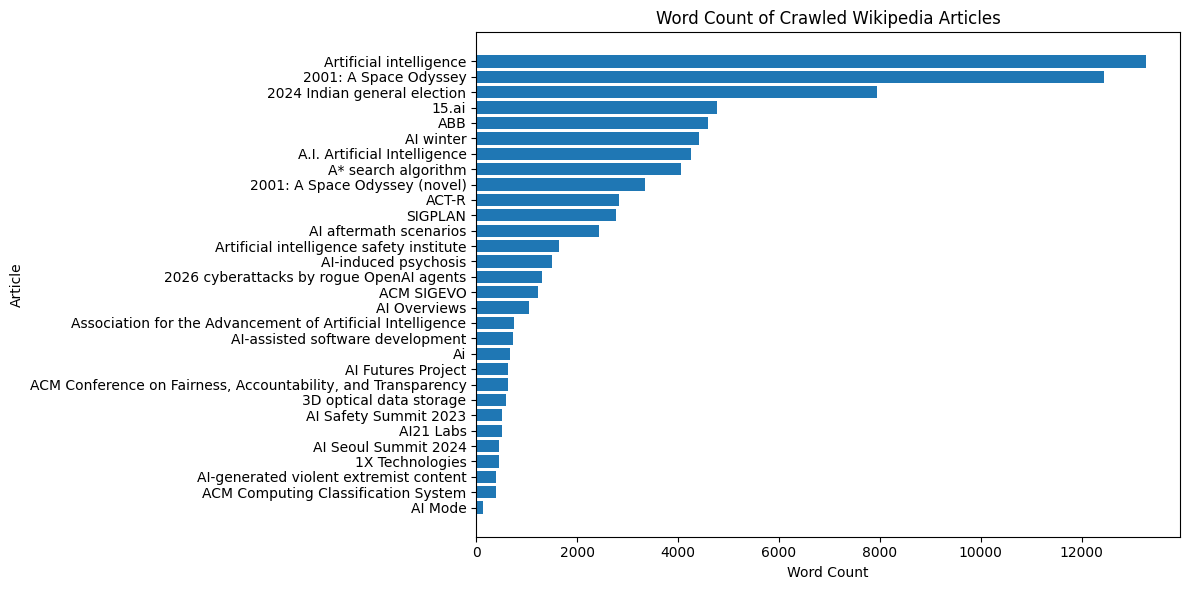

In [23]:
# Purpose: Visualize differences in the lengths of the collected articles.

import matplotlib.pyplot as plt

plot_df = pages_df.sort_values("word_count", ascending=False)

plt.figure(figsize=(12, 6))
plt.barh(plot_df["title"], plot_df["word_count"])
plt.xlabel("Word Count")
plt.ylabel("Article")
plt.title("Word Count of Crawled Wikipedia Articles")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [35]:
# Purpose: Convert article text into lowercase words and remove punctuation.

import re
from collections import Counter

def tokenize(text):
    return re.findall(r"\b[a-z]{2,}\b", text.lower())

pages_df["tokens"] = pages_df["text"].apply(tokenize)

print("Sample tokens:")
print(pages_df[["title", "tokens"]].head(3))

Sample tokens:
                     title                                             tokens
0  Artificial intelligence  [artificial, intelligence, ai, is, the, capabi...
1                    15.ai  [ai, was, free, non, commercial, web, applicat...
2          1X Technologies  [technologies, is, norwegian, american, roboti...


In [36]:
# Purpose: Identify frequently occurring words across all crawled articles.

stop_words = {
    "the", "and", "for", "that", "with", "from", "this", "are",
    "was", "were", "has", "have", "had", "its", "into", "their",
    "they", "not", "but", "also", "which", "who", "when", "where",
    "been", "being", "more", "most", "such", "than", "then",
    "can", "could", "would", "should", "about", "after", "before",
    "other", "some", "many", "each", "both", "only", "over",
    "under", "between", "using", "used", "use", "one", "two",
    "new", "all", "out", "you", "its", "his", "her", "our"
}

all_words = [
    word
    for tokens in pages_df["tokens"]
    for word in tokens
    if word not in stop_words
]

word_counts = Counter(all_words)

print("Top 20 frequent words:")
print(word_counts.most_common(20))

Top 20 frequent words:
[('of', 2527), ('in', 1882), ('to', 1818), ('ai', 796), ('by', 683), ('as', 637), ('on', 623), ('is', 621), ('it', 492), ('an', 332), ('film', 328), ('at', 312), ('be', 290), ('or', 256), ('kubrick', 190), ('intelligence', 180), ('artificial', 156), ('abb', 156), ('he', 149), ('human', 132)]


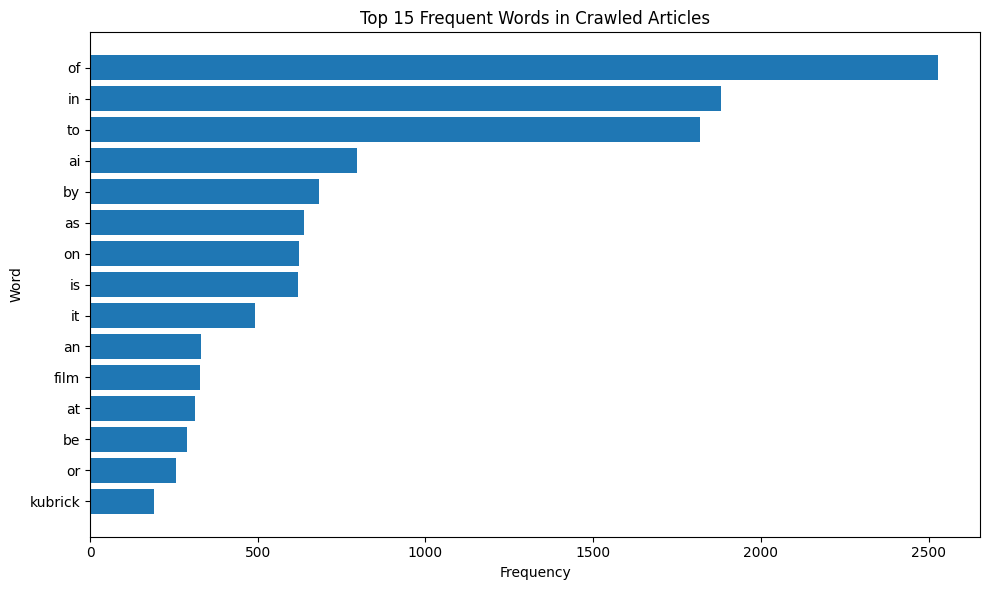

In [37]:
# Purpose: Visualize the 15 most frequent words in the collected article text.

top_words = word_counts.most_common(15)
words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(10, 6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Top 15 Frequent Words in Crawled Articles")
plt.tight_layout()
plt.show()

In [38]:
# Purpose: Keep links between the 30 crawled articles for network analysis.

article_titles = set(pages_df["title"])

network_df = links_df[
    links_df["source"].isin(article_titles)
    & links_df["target"].isin(article_titles)
].copy()

network_df = network_df.drop_duplicates(
    subset=["source", "target"]
)

print("Crawled articles:", len(article_titles))
print("Internal links:", len(network_df))
print("\nSample network links:")
display(network_df.head(10))

Crawled articles: 30
Internal links: 90

Sample network links:


,source,target
0,Artificial intelligence,15.ai
1,Artificial intelligence,1X Technologies
2,Artificial intelligence,2001: A Space Odyssey
3,Artificial intelligence,2001: A Space Odyssey (novel)
4,Artificial intelligence,2024 Indian general election
5,Artificial intelligence,2026 cyberattacks by rogue OpenAI agents
6,Artificial intelligence,3D optical data storage
7,Artificial intelligence,A* search algorithm
8,Artificial intelligence,A.I. Artificial Intelligence
10,Artificial intelligence,ABB


In [43]:
# Purpose: Remove common English stop words for meaningful text analysis.

stop_words.update({
    "of", "in", "to", "by", "as", "on", "is", "it", "an",
    "at", "be", "or", "he", "she", "they", "we", "i",
    "a", "the", "and", "for", "that", "with", "from",
    "this", "are", "was", "were", "has", "have", "had",
    "will", "would", "can", "could", "also", "been",
    "which", "who", "its", "their", "these", "those"
})

all_words = [
    word
    for tokens in pages_df["tokens"]
    for word in tokens
    if word not in stop_words
]

word_counts = Counter(all_words)

print("Top 20 meaningful words:")
print(word_counts.most_common(20))

Top 20 meaningful words:
[('ai', 796), ('film', 328), ('kubrick', 190), ('intelligence', 180), ('artificial', 156), ('abb', 156), ('human', 132), ('first', 131), ('research', 121), ('data', 116), ('may', 107), ('million', 99), ('including', 98), ('space', 94), ('time', 94), ('act', 94), ('learning', 93), ('systems', 89), ('voice', 88), ('based', 87)]


In [54]:
# Purpose: Create an interactive chart of the 15 most frequent words.

import plotly.express as px

top_words = word_counts.most_common(15)

word_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])
word_df = word_df.sort_values("Frequency", ascending=True)

fig = px.bar(
    word_df,
    x="Frequency",
    y="Word",
    orientation="h",
    color="Frequency",
    color_continuous_scale="Viridis",
    title="Top 15 Words in Crawled Wikipedia Articles",
    hover_data={"Frequency": True, "Word": True}
)

fig.update_layout(
    template="plotly_white",
    height=600,
    coloraxis_showscale=False
)
fig.write_html("project_outputs/word_frequency.html")
fig.show()

In [55]:
# Purpose: Build the hyperlink network and calculate node connectivity.

G = nx.DiGraph()

G.add_nodes_from(pages_df["title"])
G.add_edges_from(
    zip(network_df["source"], network_df["target"])
)

in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

degree_df = pd.DataFrame({
    "Article": list(G.nodes()),
    "Incoming Links": [in_degree[n] for n in G.nodes()],
    "Outgoing Links": [out_degree[n] for n in G.nodes()]
})

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

print("\nTop 10 articles by incoming links:")
display(
    degree_df.sort_values("Incoming Links", ascending=False).head(10)
)

print("\nTop 10 articles by outgoing links:")
display(
    degree_df.sort_values("Outgoing Links", ascending=False).head(10)
)

Nodes: 30
Edges: 90

Top 10 articles by incoming links:


,Article,Incoming Links,Outgoing Links
0,Artificial intelligence,20,26
28,AI winter,7,8
19,AI-induced psychosis,5,6
16,ACT-R,4,4
3,2001: A Space Odyssey,4,3
1,15.ai,4,5
17,AI-assisted software development,4,5
26,AI Safety Summit 2023,3,1
18,AI-generated violent extremist content,3,3
20,AI21 Labs,3,1



Top 10 articles by outgoing links:


,Article,Incoming Links,Outgoing Links
0,Artificial intelligence,20,26
28,AI winter,7,8
19,AI-induced psychosis,5,6
17,AI-assisted software development,4,5
1,15.ai,4,5
16,ACT-R,4,4
3,2001: A Space Odyssey,4,3
25,Artificial intelligence safety institute,0,3
14,ACM SIGEVO,3,3
18,AI-generated violent extremist content,3,3


In [56]:
# Purpose: Visualize the Wikipedia hyperlink network interactively.

import plotly.graph_objects as go
import numpy as np

# Create a reproducible network layout.
pos = nx.spring_layout(G, seed=42, k=0.8, iterations=100)

# Prepare edge coordinates.
edge_x, edge_y = [], []

for source, target in G.edges():
    x0, y0 = pos[source]
    x1, y1 = pos[target]

    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x,
    y=edge_y,
    mode="lines",
    line=dict(width=0.7, color="rgba(120,120,120,0.4)"),
    hoverinfo="skip",
    name="Hyperlinks"
)

# Assign node colors based on incoming-link counts.
node_x = [pos[n][0] for n in G.nodes()]
node_y = [pos[n][1] for n in G.nodes()]
node_names = list(G.nodes())
node_in = [in_degree[n] for n in node_names]
node_out = [out_degree[n] for n in node_names]

node_trace = go.Scatter(
    x=node_x,
    y=node_y,
    mode="markers+text",
    text=node_names,
    textposition="top center",
    textfont=dict(size=9),
    customdata=np.column_stack([node_in, node_out]),
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Incoming links: %{customdata[0]}<br>"
        "Outgoing links: %{customdata[1]}"
        "<extra></extra>"
    ),
    marker=dict(
        size=[12 + 3 * d for d in node_in],
        color=node_in,
        colorscale="Turbo",
        showscale=True,
        colorbar=dict(title="Incoming<br>links"),
        line=dict(width=1, color="white")
    ),
    name="Articles"
)

fig = go.Figure(data=[edge_trace, node_trace])

fig.update_layout(
    title="Interactive Wikipedia Article Hyperlink Network",
    template="plotly_dark",
    showlegend=False,
    hovermode="closest",
    height=800,
    margin=dict(l=20, r=20, t=60, b=20),
    xaxis=dict(visible=False),
    yaxis=dict(visible=False)
)

fig.show()

In [57]:
# Purpose: Export interactive visualizations and analysis results.

from pathlib import Path

output_dir = Path("project_outputs")
output_dir.mkdir(exist_ok=True)

# Save interactive charts.
fig.write_html(output_dir / "wikipedia_network.html")

In [58]:

# Script 21: Export project datasets, interactive graphs, and statistics

from pathlib import Path
import shutil
import pandas as pd
import zipfile

# 1. Create output folder
output_dir = Path("project_outputs")
output_dir.mkdir(exist_ok=True)

# 2. Save datasets
pages_df.drop(columns=["tokens"], errors="ignore").to_csv(
    output_dir / "wikipedia_articles.csv", index=False
)
links_df.to_csv(output_dir / "all_wikipedia_links.csv", index=False)
network_df.to_csv(output_dir / "internal_links.csv", index=False)
degree_df.to_csv(output_dir / "network_statistics.csv", index=False)

# 3. Recreate the interactive word-frequency chart
top_words = word_counts.most_common(15)
word_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])

word_fig = px.bar(
    word_df.sort_values("Frequency"),
    x="Frequency",
    y="Word",
    orientation="h",
    color="Frequency",
    color_continuous_scale="Viridis",
    title="Top 15 Words in Crawled Wikipedia Articles"
)
word_fig.update_layout(template="plotly_white", height=600)
word_fig.write_html(output_dir / "word_frequency.html")

# 4. Recreate the interactive network graph
pos = nx.spring_layout(G, seed=42, k=0.8, iterations=100)

edge_x, edge_y = [], []
for source, target in G.edges():
    x0, y0 = pos[source]
    x1, y1 = pos[target]
    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x, y=edge_y, mode="lines",
    line=dict(width=0.7, color="rgba(150,150,150,0.45)"),
    hoverinfo="skip"
)

nodes = list(G.nodes())
node_trace = go.Scatter(
    x=[pos[n][0] for n in nodes],
    y=[pos[n][1] for n in nodes],
    mode="markers+text",
    text=nodes,
    textposition="top center",
    textfont=dict(size=9),
    customdata=[[in_degree[n], out_degree[n]] for n in nodes],
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Incoming links: %{customdata[0]}<br>"
        "Outgoing links: %{customdata[1]}<extra></extra>"
    ),
    marker=dict(
        size=[12 + 3 * in_degree[n] for n in nodes],
        color=[in_degree[n] for n in nodes],
        colorscale="Turbo",
        showscale=True,
        colorbar=dict(title="Incoming links"),
        line=dict(width=1, color="white")
    )
)

network_fig = go.Figure([edge_trace, node_trace])
network_fig.update_layout(
    title="Interactive Wikipedia Article Hyperlink Network",
    template="plotly_dark",
    showlegend=False,
    hovermode="closest",
    height=800,
    xaxis=dict(visible=False),
    yaxis=dict(visible=False)
)
network_fig.write_html(output_dir / "wikipedia_network.html")

# 5. Save the top-word frequency table
pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
).to_csv(output_dir / "top_words.csv", index=False)

# 6. Package everything into one ZIP file
zip_path = Path("wikipedia_crawler_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for file in output_dir.iterdir():
        if file.is_file():
            archive.write(file, arcname=f"project_outputs/{file.name}")

print("SUCCESS! All outputs saved.")
print("Folder:", output_dir.resolve())
print("ZIP:", zip_path.resolve())
print("\nFiles created:")
for file in sorted(output_dir.iterdir()):
    print("-", file.name)


SUCCESS! All outputs saved.
Folder: /content/project_outputs
ZIP: /content/wikipedia_crawler_outputs.zip

Files created:
- all_wikipedia_links.csv
- internal_links.csv
- network_statistics.csv
- top_words.csv
- wikipedia_articles.csv
- wikipedia_network.html
- word_frequency.html


In [59]:
from google.colab import files
files.download("wikipedia_crawler_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>